# First attempt at parameter estimation architecture

In [1]:
from pygom.model.pygom_model import Model
from pygom.model.transition import Transition
from dataclasses import dataclass
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt


## Observables of the system ##

class Observable:
    """
    How to generate the observable from the simulation output
    """
    name = None

    def evaluate(self, simulation_output):
        """
        Overloaded by child classes
        """
        raise NotImplementedError

@dataclass
class Target:
    """
    What the numerical target value of the observable is
    """
    observable: Observable
    value: float
    weight: float = 1.0

## Unknown states or initial conditions ##

@dataclass
class Unknown:
    id: str
    lower: float | None = 0.0
    upper: float | None = np.inf

@dataclass
class UnknownSpec:
    parameters: list[Unknown]
    initial_states: list[Unknown]

## Simulation ##

class Simulator:
    def simulate(self, model):
        raise NotImplementedError

class DeterministicSimulator(Simulator):
    def __init__(self, times):
        self.times = times

    def simulate(self, model):
        return model.solve_deterministic(self.times, method="RK45")[0].result

class StochasticSimulator(Simulator):
    """
    A non working example of what we might want from a stochastic simulator
    where we discard those that go extinct 
    """
    def __init__(self, n_runs=10, discard_extinct=True):
        self.n_runs = n_runs
        self.discard_extinct = discard_extinct

    def simulate(self, model):

        out = []
        for _ in range(self.n_runs):
            sim = model.solve_stochastic(...)
            if self.discard_extinct and self.is_extinct(sim):
                continue
            out.append(sim)

        return out

## Loss functions ##

class Loss:
    def evaluate(
        self,
        observed,
        predicted
    ):
        raise NotImplementedError

class RelativeSquaredError(Loss):

    def evaluate(self, observed, predicted):

        observed = np.asarray(observed)
        predicted = np.asarray(predicted)

        rel_err = (
            predicted - observed
        ) / np.maximum(np.abs(observed), 1e-8)

        return np.sum(rel_err**2)

# ... plus all other loss functions Square, Normal, NegBinom etc

## Main parameter estimation class ##

class ParameterEstimation:
    def __init__(
        self,
        model,      # model with known params/ICs already declared
        unknown_spec,
        simulator,
        targets,
        loss
    ):

        self.model = model
        self.unknown_spec = unknown_spec
        self.simulator = simulator
        self.targets = targets
        self.loss = loss

    def unpack_theta(self, theta):
        """
        Safely unpack unknown variables from list to dict which
        can then be fed into the right place in the model.
        """

        n_params = len(self.unknown_spec.parameters)

        params = {
            u.id: value
            for u, value
            in zip(self.unknown_spec.parameters, theta[:n_params])
        }

        initial_states = {
            u.id: value
            for u, value
            in zip(self.unknown_spec.initial_states, theta[n_params:])
        }

        return params, initial_states

    def configure_model(self, theta):
        """
        Parameterise the model, ready for simulation
        """

        params, states = self.unpack_theta(theta)

        self.model.parameters = params
        self.model.initial_states = states

        return self.model

    def objective(self, theta):
        """
        Calculate loss, given trial parameters
        """

        sim = self.simulator.simulate(self.configure_model(theta))

        loss = 0
        for target in self.targets:
            predicted = target.observable.evaluate(sim)
            loss += target.weight * self.loss.evaluate(target.value, predicted)

        return loss

    def mle(self, x0):
        """
        Optimise loss function to obtain MLE params and/or initial states
        """

        unknowns = self.unknown_spec.parameters + self.unknown_spec.initial_states

        bounds = []
        for u in unknowns:
            bounds.append( (u.lower, u.upper) )

        res = minimize(
            fun=self.objective,
            x0=x0,
            bounds=bounds
        )

        params, states = self.unpack_theta(res.x)

        return {
            "parameters": params,
            "initial_states": states,
            "success": res.success,
            "loss": res.fun,
        }

    # option to optimise via abc
    # def abc():


# Examples

We use an SEIR model as our example system

In [2]:
## define pygom model ##

states = ['S', 'E', 'I', 'R']
params = ['beta', 'alpha', 'gamma']
derived_params = [('N', 'S+E+I+R')]

inf = Transition(origin='S', destination='E', rate='beta*S*I/N')
prog = Transition(origin='E', destination='I', rate='alpha*E')
rec = Transition(origin='I', destination='R', rate='gamma*I')

event_list = [inf, prog, rec]
mod = Model(state=states, param=params, derived_param=derived_params, event=event_list)

## Example 1

This is less a parmeter-estimation-from-data exercise and more like model calibration.

Let's say we want to adjust 2 parameters (gamma and beta) in order to obtain certain values for final size and growth rate.

In theory, this could also be done algebraicly via pygom's symbolic expressions.

In [3]:
## declare known values ##

mod.parameters = {
    'alpha': 0.5
}

mod.initial_states = {
    'S': 1000,
    'E': 1,
    'I': 0,
    'R': 0
}

## declare unknwon variables and domain we wish to explore ##

unknown_spec = UnknownSpec(
    parameters=[
        Unknown('beta', 0, 1),
        Unknown('gamma', 0, 1)
    ],
    initial_states=[]
)

## Define observables ##

class FinalSize(Observable):
    name = "final_size"

    def evaluate(self, simulation_output):

        N = simulation_output.y[0, :].sum()
        final_size = simulation_output.y[-1, 3] / N     # TODO: get the index of 'R' compartment from model_spec

        return final_size

class GrowthRate(Observable):
    name = "growth_rate"

    def evaluate(self, simulation_output):
        # start and end indices to calculate growth between
        i1 = 10
        i2 = 20

        dt = simulation_output.t[i2] - simulation_output.t[i1]
        inf_ratio = simulation_output.y[i2, 1] / simulation_output.y[i1, 1]        # TODO: get the index of 'I' compartment from model_spec

        growth_rate = np.log(inf_ratio) / dt

        return growth_rate
    
## Observables and their target values ##

targets = [
    Target(FinalSize(), 0.8),
    Target(GrowthRate(), 0.1),
]

## Simulation is simple deterministic for 200 days ##

times = np.arange(0, 200, 1)
simulator = DeterministicSimulator(times)

## Build estimator class and get MLE ##

estimator = ParameterEstimation(
    model = mod,
    unknown_spec = unknown_spec,
    simulator = simulator,
    targets = targets,
    loss = RelativeSquaredError()
)

estimator.mle(x0=[0.4, 0.2])

{'parameters': {'beta': np.float64(0.30484621874871554),
  'gamma': np.float64(0.1516170148798469)},
 'initial_states': {},
 'success': True,
 'loss': np.float64(1.4257988373082292e-13)}

## Example 2

The classic epi fitting exercise: estimate epi params to fit an infection time series.
We also allow the initial number of exposed individuals to be unknown.

NOTE: for this simple exaple, we are fitting prevalence instead of incidence

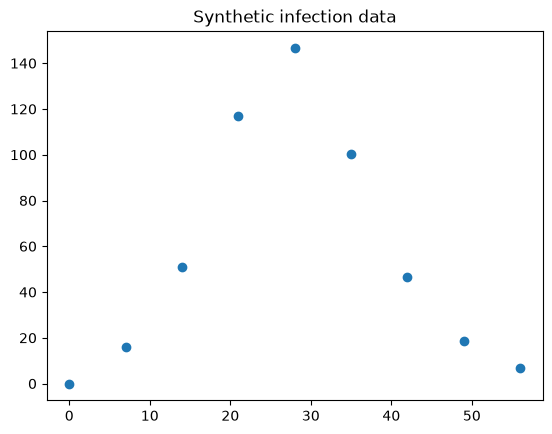

In [4]:
## generate synthetic data ##

mod.parameters = {
    'alpha': 0.5,
    'beta': 0.6,
    'gamma': 0.25
}

mod.initial_states = {
    'S': 1000,
    'E': 10,
    'I': 0,
    'R': 0
}

# weekly data
t = np.arange(0, 60, 7)
out = mod.solve_deterministic(t)

t_data = out[0].result.t
I_data = out[0].result.y[:, 2]

plt.scatter(t_data, I_data)
plt.title("Synthetic infection data")
plt.show()

In [5]:
## declare known values ##

mod.parameters = {
    'alpha': 0.5
}

mod.initial_states = {
    'S': 1000,
    'I': 0,
    'R': 0
}

## declare unknwon variables ##

unknown_spec = UnknownSpec(
    parameters=[
        Unknown('beta', 0, 1),
        Unknown('gamma', 0, 1)
    ],
    initial_states=[
        Unknown('E', 1, 100)
    ]
)

## Define observables ##

# NOTE: this can very easily become a standard class that the user can
#       invoke via some nice API.
class InfectionTimeSeries(Observable):
    name = "infection_time_series"

    def evaluate(self, simulation_output):
        infections = simulation_output.y[:, 2]

        return infections
    
## Observables and their target values ##

targets = [
    Target(InfectionTimeSeries(), I_data),
]

## Simulation is simple deterministic ##

times = t_data
simulator = DeterministicSimulator(times)

## Build estimator class and get MLE ##

estimator = ParameterEstimation(
    model = mod,
    unknown_spec = unknown_spec,
    simulator = simulator,
    targets = targets,
    loss = RelativeSquaredError()
)

estimator.mle(x0=[0.4, 0.2, 5])

{'parameters': {'beta': np.float64(0.6000483181494988),
  'gamma': np.float64(0.24989273780341942)},
 'initial_states': {'E': np.float64(9.98649263699101)},
 'success': True,
 'loss': np.float64(1.3181855075395922e-05)}